In [2]:
import matplotlib as mpl
import seaborn as sns
import importlib

# Seaborn theme
sns.set_theme(
    style="ticks",        # "white", "whitegrid", "ticks", "darkgrid"
    context="paper",       # notebook, paper, talk, poster
    palette="deep"
)

# Your publication formatting
mpl.rcParams.update({

    # Fonts
    "font.family": "Arial",
    "font.size": 14,

    # Figure titles
    "figure.titlesize": 34,
    "figure.titleweight": "bold",

    # Axes titles/labels
    "axes.titlesize": 14,
    "axes.labelsize": 14,

    # Tick labels
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,

    # Legend
    "legend.fontsize": 16,
    "legend.title_fontsize": 18,

    # Lines & markers
    "lines.linewidth": 3,
    "lines.markersize": 8,

    # Axes
    "axes.linewidth": 2,

    # Ticks
    "xtick.major.size": 8,
    "ytick.major.size": 8,
    "xtick.major.width": 2,
    "ytick.major.width": 2,
    "xtick.minor.size": 4,
    "ytick.minor.size": 4,
    "xtick.minor.width": 1.5,
    "ytick.minor.width": 1.5,

    # Grid
    "grid.linewidth": 1,
    "grid.alpha": 0.3,

    # Export
    "figure.dpi": 150,
    "savefig.dpi": 600,

    # Editable vector graphics
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

In [5]:
import os

import biosensor_history_viewer
from biosensor_history_viewer import launch_history_viewer
importlib.reload(biosensor_history_viewer)

# Change this to the path where your simulation data is stored
data_root = "/Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260818_nanospike_branches_per_segment_sweep"

kinetics_csv = os.path.join(data_root, "1to1_kinetics.csv")

viewer = launch_history_viewer(
    data_root,
    figsize=(10, 6),
    ylim=(0.0, 0.12),
    # xlim=(0.0, 1000.0),
)

In [20]:
!python fit_1to1_kinetics.py \
    --data-root "$data_root" \
    --output-csv "$kinetics_csv"

Found 10 replicate history files.
[1/10] /Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260916_funnel_trap_array_equilibration/funnel_throat_radius_m_5e-09/replicate_001
    kon=2.082e+05 M^-1 s^-1, koff=0.02171 s^-1, KD=104.2 nM, R2_assoc=0.7233, R2_diss=0.9141
[2/10] /Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260916_funnel_trap_array_equilibration/funnel_throat_radius_m_5e-09/replicate_002
    kon=1.671e+05 M^-1 s^-1, koff=0.01737 s^-1, KD=103.9 nM, R2_assoc=0.7994, R2_diss=0.9734
[3/10] /Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260916_funnel_trap_array_equilibration/funnel_throat_radius_m_5e-09/replicate_003
    kon=1.741e+05 M^-1 s^-1, koff=0.01808 s^-1, KD=103.9 nM, R2_assoc=0.8158, R2_diss=0.9408
[4/10] /Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260916_funnel_tra

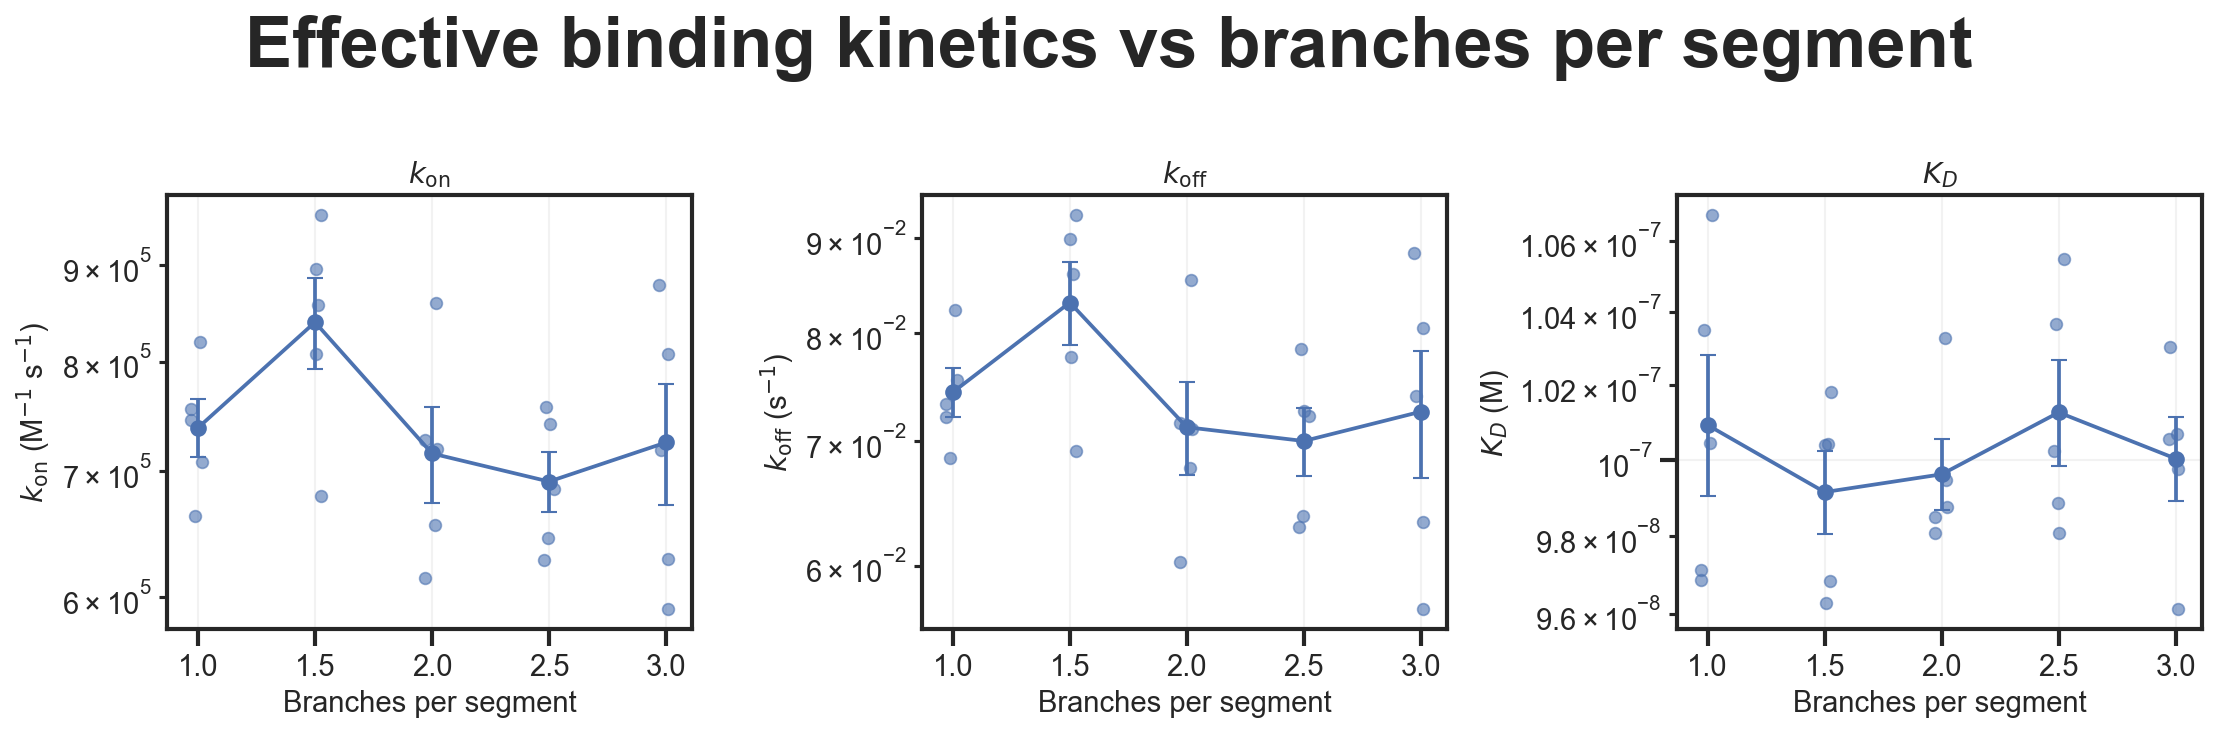

In [6]:
import compare_geometry_kinetics
importlib.reload(compare_geometry_kinetics)
from compare_geometry_kinetics import (
    load_kinetic_sweep,
    plot_kinetic_sweep,
)


data = load_kinetic_sweep(
    kinetics_csv
)

fig, axes = plot_kinetic_sweep(
    data,
    log_x=False,
)

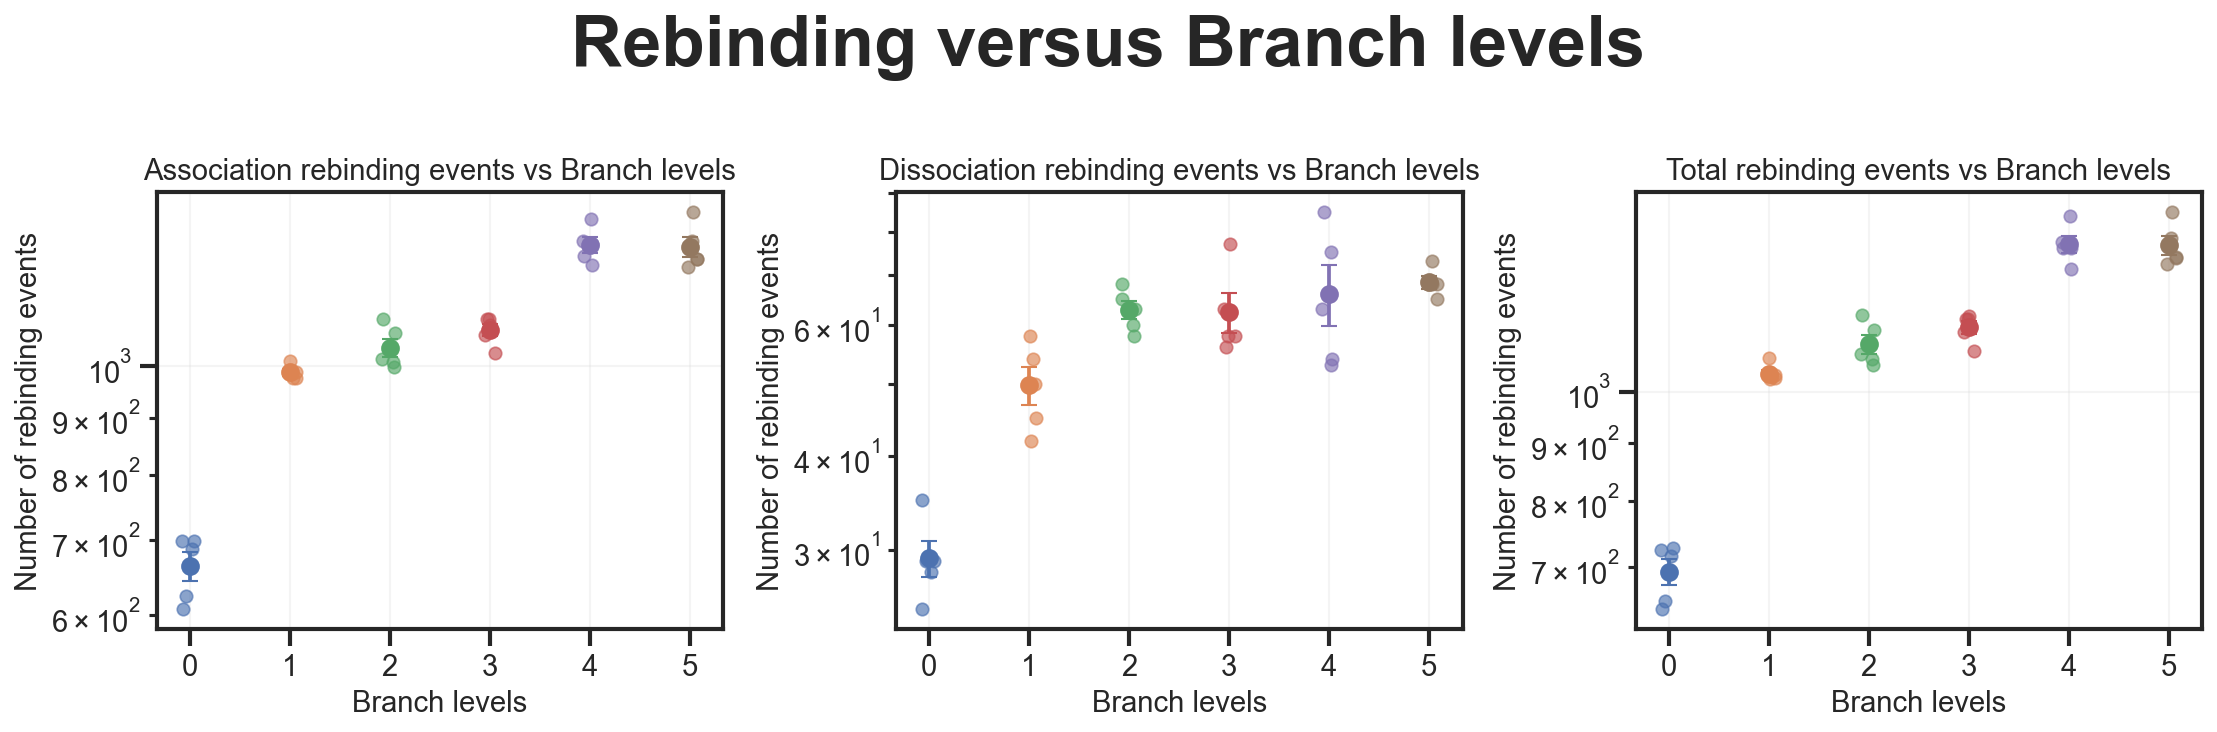

In [17]:
import compare_geometry_rebinding_with_kinetics
importlib.reload(compare_geometry_rebinding_with_kinetics)
from compare_geometry_rebinding_with_kinetics import (
    load_rebinding_sweep,
    summarize_rebinding,
    plot_rebinding_sweep,
)

data = load_rebinding_sweep(
    data_root
)

summary = summarize_rebinding(data)

fig, axes = plot_rebinding_sweep(
    data,
    log_x=False,
    log_y=True,
)

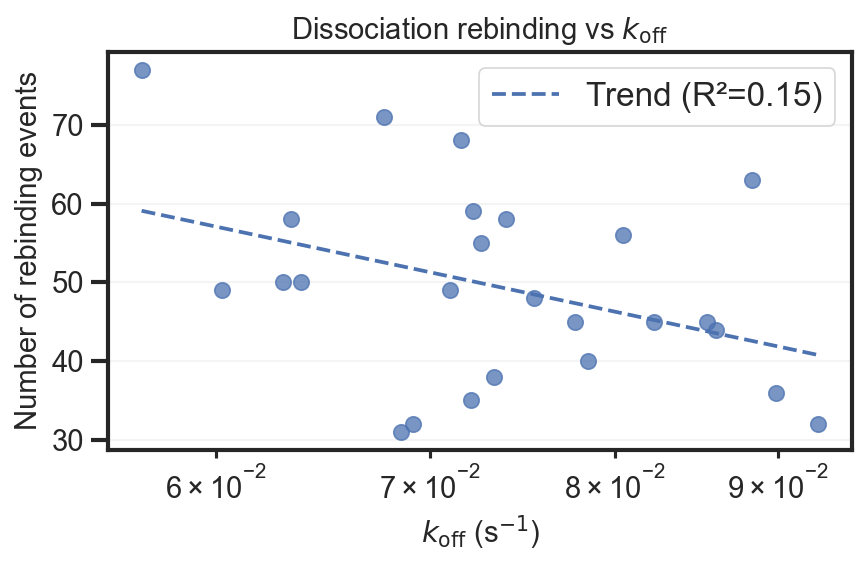

In [14]:
import compare_geometry_rebinding_with_kinetics
importlib.reload(compare_geometry_rebinding_with_kinetics)
from compare_geometry_rebinding_with_kinetics import (
    load_rebinding_sweep,
    load_rebinding_with_kinetics,
    plot_rebinding_vs_kinetic_parameter,
)

# 1. Load rebinding results from simulation histories
rebinding_data = load_rebinding_sweep(
    data_root)

# 2. Merge with the CSV produced by the sweep-aware 1:1 kinetic fitter
data = load_rebinding_with_kinetics(
    rebinding_data,
    kinetics_csv
)

# 3. Now k_on, k_off, and K_D exist
fig, ax = plot_rebinding_vs_kinetic_parameter(
    data=data,
    parameter="k_off",
    phase="dissociation",
    figsize=(6, 4),
    log_y=False
)